In [1]:
#import the necessary frameworks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#load data set
df = pd.read_csv("POP.csv", header=None)
df.head(10)

,0,1,2,3,4,5
0,NaN,Population 2022,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,Ranking,NaN,Economy,(thousands),NaN
4,NaN,NaN,NaN,NaN,NaN,NaN
5,IND,1,NaN,India,"1,417,173",NaN
6,CHN,2,NaN,China,"1,412,175",NaN
7,USA,3,NaN,United States,"333,288",NaN
8,IDN,4,NaN,Indonesia,"275,501",NaN
9,PAK,5,NaN,Pakistan,"235,825",NaN


In [10]:
#initial Data Analysis (IDA)
#1.shape of the data
df.shape

(329, 6)

In [11]:
#2.no of columns
df.columns

Index([0, 1, 2, 3, 4, 5], dtype='int64')

In [12]:
#3.dafa types
df.dtypes

0     object
1     object
2    float64
3     object
4     object
5     object
dtype: object

In [13]:
#4.completeness of the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 329 entries, 0 to 328
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   0       229 non-null    object 
 1   1       221 non-null    object 
 2   2       0 non-null      float64
 3   3       230 non-null    object 
 4   4       230 non-null    object 
 5   5       2 non-null      object 
dtypes: float64(1), object(5)
memory usage: 15.6+ KB


In [14]:
#5.descriptive statistics of the columns
df.describe
df.describe(include='all')

,0,1,2,3,4,5
count,229,221,0.0,230,230,2
unique,229,221,NaN,230,230,2
top,IND,Population 2022,NaN,Economy,(thousands),a
freq,1,1,NaN,1,1,1
mean,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
#6.missing values
df.isnull().sum()

0    100
1    108
2    329
3     99
4     99
5    327
dtype: int64

In [16]:
#7.duplicates
df.duplicated().sum()

np.int64(95)

In [17]:
#8.count unique values in ecah column
for col in df.columns:
    print(f"{col}:{df[col].nunique()}unique values")

0:229unique values
1:221unique values
2:0unique values
3:230unique values
4:230unique values
5:2unique values


In [18]:
#data wrangling#data cleaning#data preprocessing
#1.Remove unnecessary columns
population = df.drop(columns=[2, 5])
population.head()

,0,1,3,4
0,NaN,Population 2022,NaN,NaN
1,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN
3,NaN,Ranking,Economy,(thousands)
4,NaN,NaN,NaN,NaN


In [19]:
#2.Remove unnecessary heading and blank rows
population = population.drop(index=[0, 1, 2, 3, 4])
population.head()

,0,1,3,4
5,IND,1,India,"1,417,173"
6,CHN,2,China,"1,412,175"
7,USA,3,United States,"333,288"
8,IDN,4,Indonesia,"275,501"
9,PAK,5,Pakistan,"235,825"


In [23]:
#3.rename columns
population = population.rename(columns={
    0: "Country Code",
    1: "Rank",
    3: "Country",
    4: "Population"
})
population.head()


,Country Code,Rank,Country,Population
5,IND,1,India,"1,417,173"
6,CHN,2,China,"1,412,175"
7,USA,3,United States,"333,288"
8,IDN,4,Indonesia,"275,501"
9,PAK,5,Pakistan,"235,825"


In [26]:
#4.handling missing values
population["Country Code"] = population["Country Code"].fillna("Unknown")
population["Country"] = population["Country"].fillna("Unknown")
population.head()

,Country Code,Rank,Country,Population
5,IND,1,India,1417173.0
6,CHN,2,China,1412175.0
7,USA,3,United States,333288.0
8,IDN,4,Indonesia,275501.0
9,PAK,5,Pakistan,235825.0


In [27]:
#5.convert categorical values into categorical data types
population["Country"] = population["Country"].astype("category")
population["Country Code"] = population["Country Code"].astype("category")
population.dtypes


Country Code    category
Rank              object
Country         category
Population       float64
dtype: object

In [30]:
# remove rows with missing population values
population = population.dropna(subset=["Population"])

In [31]:
population.shape

(229, 4)

In [32]:
# exploratory data analysis (EDA)
# population statistics
print("Population statistics:\n", population["Population"].describe())

Population statistics:
 count    2.290000e+02
mean     1.386599e+05
std      6.483263e+05
min      1.100000e+01
25%      1.121000e+03
50%      7.346000e+03
75%      3.369700e+04
max      7.951150e+06
Name: Population, dtype: float64


In [38]:
# analysis population by country
print("Population by country:\n",
      population.groupby("Country", observed=True)["Population"].sum())

Population by country:
 Country
Afghanistan             41129.0
Albania                  2776.0
Algeria                 44903.0
American Samoa             44.0
Andorra                    80.0
                        ...    
West Bank and Gaza       5044.0
World                 7951150.0
Yemen, Rep.             33697.0
Zambia                  20018.0
Zimbabwe                16321.0
Name: Population, Length: 229, dtype: float64


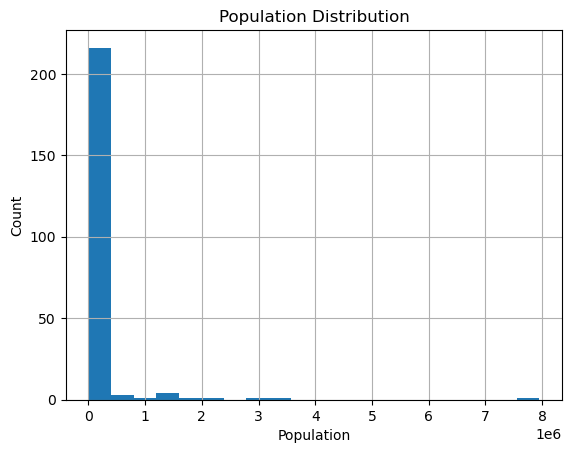

In [45]:
# visualize population distribution
population["Population"].hist(bins=20)
plt.title("Population Distribution")
plt.xlabel("Population")
plt.ylabel("Count")
plt.show()

In [55]:
# convert rank into numeric values
population["Rank"] = pd.to_numeric(
    population["Rank"], errors="coerce"
)
# select top 5 countries
top5 = population[population["Rank"].between(1, 5)].copy()
# convert country to string for plotting
top5["Country"] = top5["Country"].astype(str)
top5

,Country Code,Rank,Country,Population
5,IND,1,India,1417173.0
6,CHN,2,China,1412175.0
7,USA,3,United States,333288.0
8,IDN,4,Indonesia,275501.0
9,PAK,5,Pakistan,235825.0


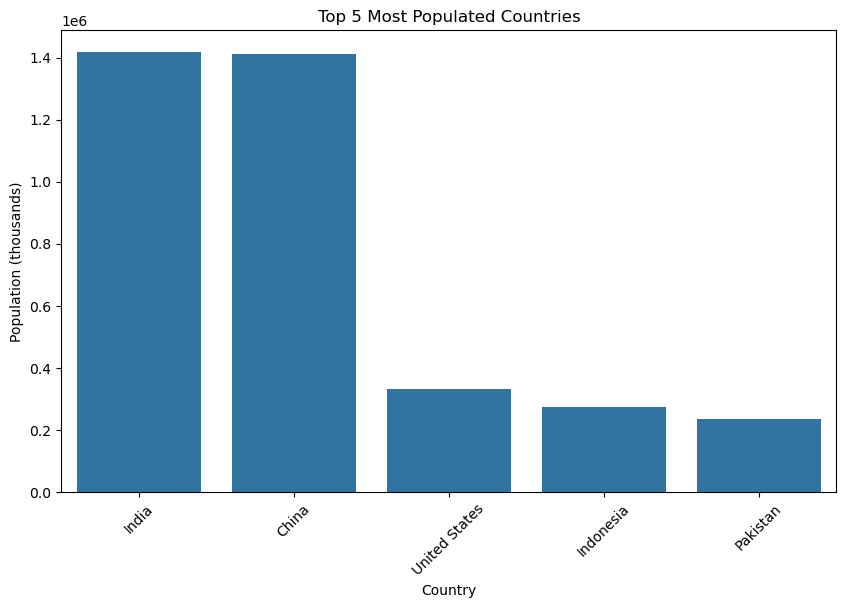

In [56]:
# visualize top 5 most populated countries
plt.figure(figsize=(10, 6))
sns.barplot(
    x="Country",
    y="Population",
    data=top5
)
plt.title("Top 5 Most Populated Countries")
plt.xlabel("Country")
plt.ylabel("Population (thousands)")
plt.xticks(rotation=45)
plt.show()

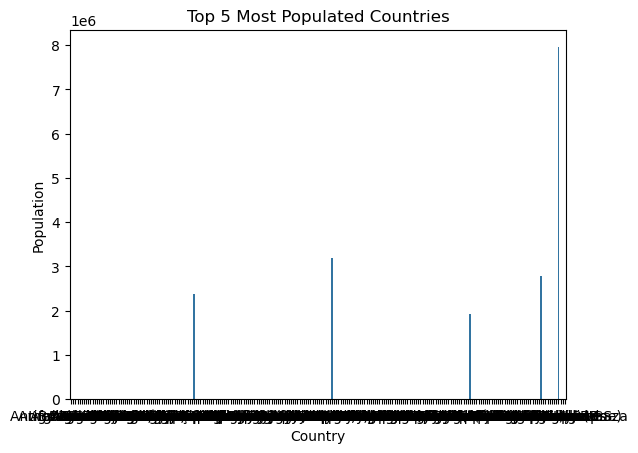

In [57]:
#top 5 most populated countries
top5 = population.nlargest(5, "Population")
sns.barplot(
    x="Country",
    y="Population",
    data=top5
)
plt.title("Top 5 Most Populated Countries")
plt.xlabel("Country")
plt.ylabel("Population")
plt.show()

In [58]:
print("Population statistics:\n", population["Population"].describe())

Population statistics:
 count    2.290000e+02
mean     1.386599e+05
std      6.483263e+05
min      1.100000e+01
25%      1.121000e+03
50%      7.346000e+03
75%      3.369700e+04
max      7.951150e+06
Name: Population, dtype: float64


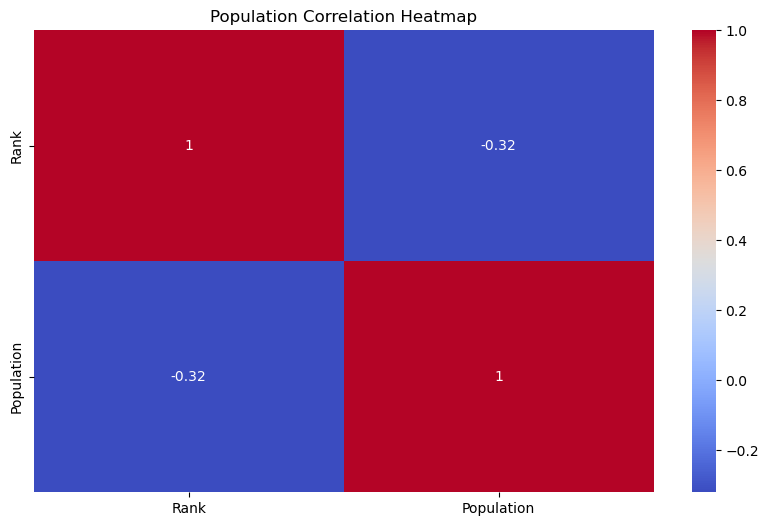

In [60]:
#correlation heatmap
plt.figure(figsize=(10,6))
sns.heatmap(
    population.corr(numeric_only=True),
    cmap='coolwarm',
    annot=True
)
plt.title("Population Correlation Heatmap")
plt.show()